In [25]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns 
from KMeans import CustomKMeans
from sklearn.datasets import make_blobs
import warnings 

warnings.filterwarnings('ignore')

In [39]:
centroids = [
    (-5, -5, 0), 
    (5, 5, 5), 
    (-2.5, 2.5, -2.5), 
    (2.5, -2.5, 2.5)
]
cluster_std = [1, 1, 1, 1]

X, y = make_blobs(
    n_samples=100, 
    cluster_std=cluster_std, 
    centers=centroids, 
    n_features=3,        
    random_state=42
)

X

array([[ 2.71645859, -2.45442816,  1.84839965],
       [-1.84860875,  2.18473076, -1.74103078],
       [ 2.6990597 , -3.10021688,  2.56980208],
       [ 2.51023306, -3.48150865,  2.96210347],
       [-5.47917424, -5.18565898, -1.10633497],
       [ 2.90498171, -3.76088395,  3.41786195],
       [-2.08721907,  3.32206016, -0.60320702],
       [ 2.1146864 , -2.38648265,  3.16213067],
       [ 5.29612028,  5.26105527,  5.00511346],
       [ 2.68645431, -3.16178646,  3.35243333],
       [ 4.67233785,  4.60789185,  3.53648505],
       [ 2.24743185, -3.74778318,  4.1324113 ],
       [-5.11564828, -5.3011037 , -1.47852199],
       [ 6.30714275,  3.39251677,  5.18463386],
       [-3.42078718, -4.23256527, -0.46947439],
       [-3.31581028,  2.42289829, -2.15884803],
       [ 4.49652435,  3.44933657,  5.06856297],
       [ 5.8219025 ,  5.08704707,  4.70099265],
       [ 6.54993441,  4.21674671,  4.67793848],
       [ 4.76541287,  3.58462926,  4.57935468],
       [-5.56228753, -6.01283112,  0.314

In [40]:
X = pd.DataFrame(X , columns = ['Feature1', 'Feature2', 'Feature'])
X

,Feature1,Feature2,Feature
0,2.716459,-2.454428,1.848400
1,-1.848609,2.184731,-1.741031
2,2.699060,-3.100217,2.569802
3,2.510233,-3.481509,2.962103
4,-5.479174,-5.185659,-1.106335
...,...,...,...
95,-4.014847,2.053485,-1.643601
96,-5.645120,-4.638604,1.538037
97,-3.272825,2.263181,-2.985364
98,-4.624302,-5.600639,-0.291694


In [41]:
inertia = []

for i in range(1,11):
    
    kmeans = CustomKMeans(n_clusters=i)
    kmeans.fit_predict(X)
    wscc   = kmeans.inertia_score
    inertia.append(wscc)
    
    
inertia

[np.float64(4168.634865324508),
 np.float64(2074.0833351136484),
 np.float64(1161.195416090092),
 np.float64(277.50259134135854),
 np.float64(254.59604172278614),
 np.float64(240.65805217630137),
 np.float64(204.52253856310904),
 np.float64(222.54318995679628),
 np.float64(204.34627225285286),
 np.float64(172.27541911082074)]

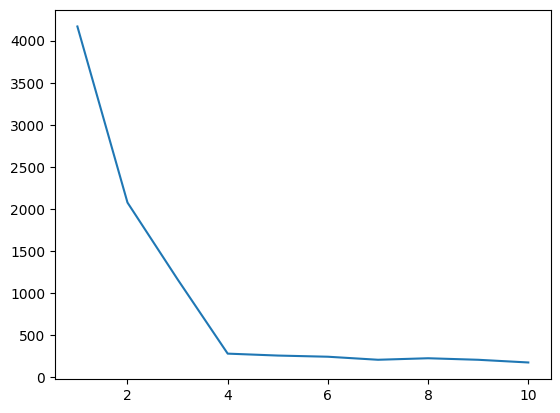

In [42]:
plt.plot(range(1,11), inertia)

In [43]:
kmeans   = CustomKMeans(n_clusters=4)
y_means = kmeans.fit_predict(X)
y_means

array([3, 2, 3, 3, 1, 3, 2, 3, 0, 3, 0, 3, 1, 0, 1, 2, 0, 0, 0, 0, 1, 2,
       1, 3, 2, 0, 0, 1, 1, 1, 0, 2, 1, 2, 2, 2, 1, 0, 2, 3, 1, 0, 3, 3,
       2, 2, 0, 1, 1, 0, 0, 3, 0, 1, 0, 1, 3, 0, 2, 0, 0, 2, 2, 3, 2, 3,
       1, 3, 2, 1, 2, 0, 2, 1, 3, 2, 3, 3, 1, 2, 3, 3, 1, 0, 3, 1, 2, 1,
       0, 2, 1, 3, 3, 3, 0, 2, 1, 2, 1, 0])

In [45]:
import plotly.express as px


fig = px.scatter_3d(
    x=X.iloc[:, 0],  
    y=X.iloc[:, 1],  
    z=X.iloc[:, 2],  
    color=y_means.astype(str),
    color_discrete_sequence=px.colors.sequential.Rainbow,
    labels={'x': 'Feature1', 'y': 'Feature2', 'z': 'Feature3', 'color': 'Cluster'},
    title="KMeans Clusters in 3D"
)

fig.update_traces(marker=dict(size=5, opacity=0.8, line=dict(width=1, color='White')))
fig.show()



<Axes: xlabel='Feature1', ylabel='Feature2'>

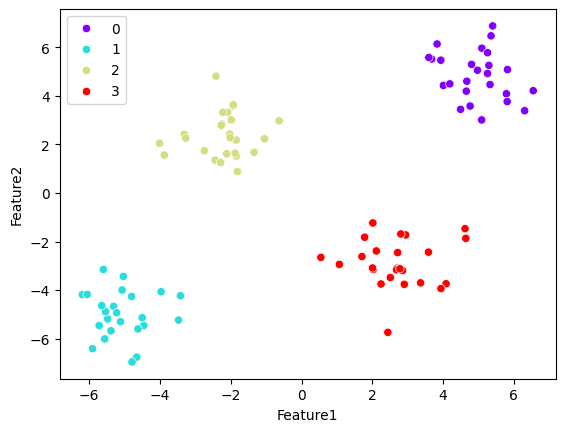

In [46]:
sns.scatterplot(x= X['Feature1'], y= X['Feature2'], hue=y_means, palette='rainbow')

In [47]:
from sklearn.metrics import adjusted_rand_score

score = adjusted_rand_score(y, y_means)

score

1.0

## **Conclusion**

**I implemented KMeans clustering on a 3-dimensional dataset with 3 features and make clusters in dataset using Custom KMeans clustering algorithm. The algorithm successfully catched the pattern in the data and made 4 clusters. As I used make_blobs of sklearn to make dataset. I compared the y_means predicted by KMeans with the true y labels and the algorithm got **1.0** means **100%** adjusted_rand_score.**